# TCS Stock: Linear Regression — OHLCV vs OHLCV + Indicators
**Target:** Next_Day_Close = Close.shift(-1) | **Split:** 80/20 time-based | **Dataset:** TCS.csv (2005–2026)

**Structure:**
1. Load data → EDA → Visualizations
2. Part A: Linear Regression on OHLCV Only (5 features)
3. Part B: Linear Regression on OHLCV + Indicators (14 features)
4. Part C: Compare A vs B
5. Part D: Overfitting / Underfitting Check

## Step 0: Data Collection — Download TCS Stock Data from Yahoo Finance

**Source:** Yahoo Finance via `yfinance` library
**Stock:** TCS.NS (TCS listed on NSE — National Stock Exchange, India)
**Period:** 2005-01-01 to 2026-09-24
**Saved as:** TCS.csv

This is the raw data collection step. The downloaded CSV contains:
Open, High, Low, Close, Volume — daily historical data adjusted for stock splits and dividends.

In [1]:
pip install yfinance

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import yfinance as yf
yf.download('TCS.NS', start='2005-01-01', end='2026-09-24').to_csv('TCS.csv')
print("TCS.csv downloaded and saved successfully!")

[*********************100%***********************]  1 of 1 completed

TCS.csv downloaded and saved successfully!


---
## Step 1: Import Libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit

print("Libraries imported successfully!")

Libraries imported successfully!


---
## Step 2: Load Dataset
`TCS.csv` has 2 extra yfinance header rows — skip with `skiprows=[1,2]`. Rename 'Price' → 'Date'.

In [57]:
df = pd.read_csv('TCS.csv', skiprows=[1, 2])
df.rename(columns={'Price': 'Date'}, inplace=True)
df['Date'] = pd.to_datetime(df['Date'])
df.set_index('Date', inplace=True)
df.sort_index(inplace=True)

for col in ['Open','High','Low','Close','Volume']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df.dropna(inplace=True)
print("Dataset loaded!")
print(f"Rows: {len(df)}")

Dataset loaded!
Rows: 5363


---
## Step 3: Dataset Overview

In [5]:
print(f"Shape     : {df.shape}")
print(f"Date Range: {df.index[0].date()} to {df.index[-1].date()}")
print(f"Columns   : {list(df.columns)}")

Shape     : (5363, 5)
Date Range: 2005-01-03 to 2026-09-23
Columns   : ['Open', 'High', 'Low', 'Close', 'Volume']


In [6]:
print("Column Names and Data Types:")
print(df.dtypes)

Column Names and Data Types:
Open      float64
High      float64
Low       float64
Close     float64
Volume      int64
dtype: object


In [7]:
print("First 5 Rows:")
df.head()

First 5 Rows:


,Open,High,Low,Close,Volume
Date,,,,,
2005-01-03,106.848537,108.547923,106.848537,108.272697,4734168
2005-01-04,108.011852,108.331887,106.664507,107.312576,4979104
2005-01-05,107.227811,107.227811,102.435290,106.011681,9604320
2005-01-06,105.611583,107.691811,103.411342,105.648384,8006888
2005-01-07,106.411726,107.611858,105.024376,107.208611,7623136


In [8]:
print("Missing Values per Column:")
print(df.isnull().sum())
print(f"Total missing: {df.isnull().sum().sum()}")

Missing Values per Column:
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64
Total missing: 0


In [9]:
print(f"Duplicate Rows: {df.duplicated().sum()}")

Duplicate Rows: 0


In [10]:
print("Statistical Summary:")
df[['Open','High','Low','Close','Volume']].describe().round(2)

Statistical Summary:


,Open,High,Low,Close,Volume
count,5363.00,5363.00,5363.00,5363.00,5363.00
mean,1344.44,1357.71,1330.29,1343.67,3350520.35
std,1188.95,1199.08,1178.30,1188.29,2819411.07
min,75.80,78.58,69.43,75.49,0.00
25%,274.27,277.70,270.58,274.01,1853218.00
50%,959.55,967.05,951.04,958.63,2650784.00
75%,2383.67,2414.17,2349.66,2376.28,3987019.00
max,4251.38,4266.48,4191.92,4230.71,88067154.00


---
## Step 4: EDA Graphs

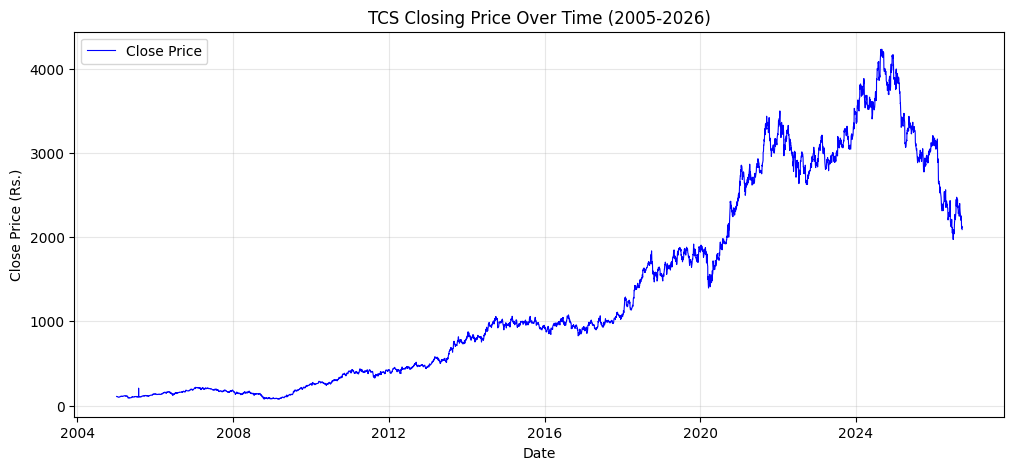

In [11]:
# Graph 1: Close Price over time
plt.figure(figsize=(12, 5))
plt.plot(df.index, df['Close'], color='blue', linewidth=0.8, label='Close Price')
plt.xlabel('Date')
plt.ylabel('Close Price (Rs.)')
plt.title('TCS Closing Price Over Time (2005-2026)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

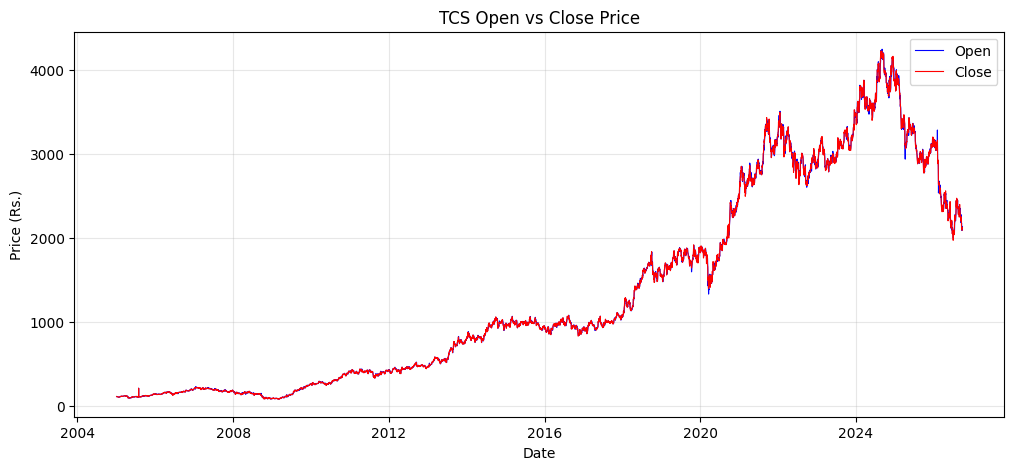

In [12]:
# Graph 2: Open vs Close
plt.figure(figsize=(12, 5))
plt.plot(df.index, df['Open'],  color='blue', linewidth=0.8, label='Open')
plt.plot(df.index, df['Close'], color='red',  linewidth=0.8, label='Close')
plt.xlabel('Date')
plt.ylabel('Price (Rs.)')
plt.title('TCS Open vs Close Price')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

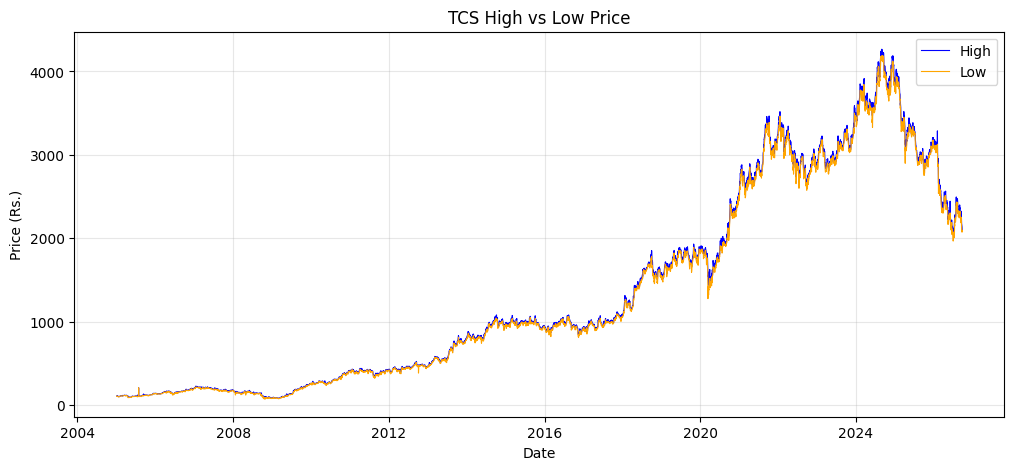

In [13]:
# Graph 3: High vs Low
plt.figure(figsize=(12, 5))
plt.plot(df.index, df['High'], color='blue',   linewidth=0.8, label='High')
plt.plot(df.index, df['Low'],  color='orange', linewidth=0.8, label='Low')
plt.xlabel('Date')
plt.ylabel('Price (Rs.)')
plt.title('TCS High vs Low Price')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

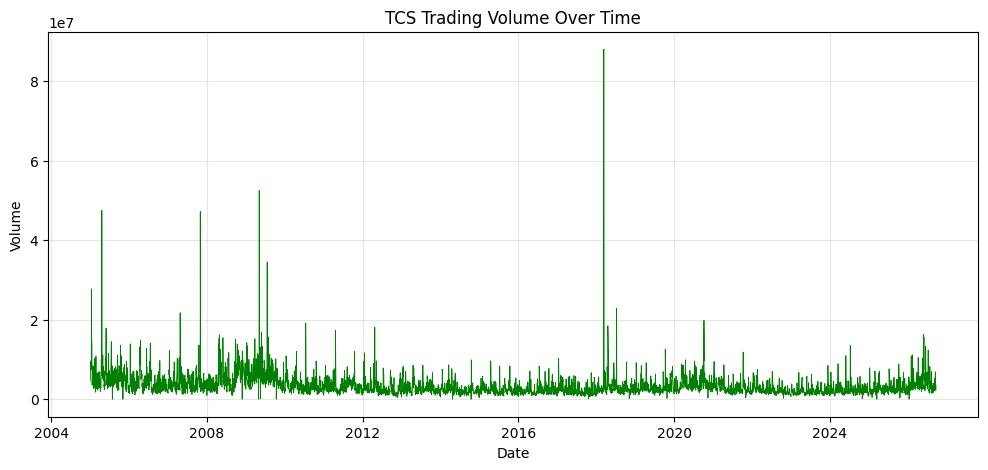

In [14]:
# Graph 4: Volume
plt.figure(figsize=(12, 5))
plt.plot(df.index, df['Volume'], color='green', linewidth=0.6)
plt.xlabel('Date')
plt.ylabel('Volume')
plt.title('TCS Trading Volume Over Time')
plt.grid(True, alpha=0.3)
plt.show()

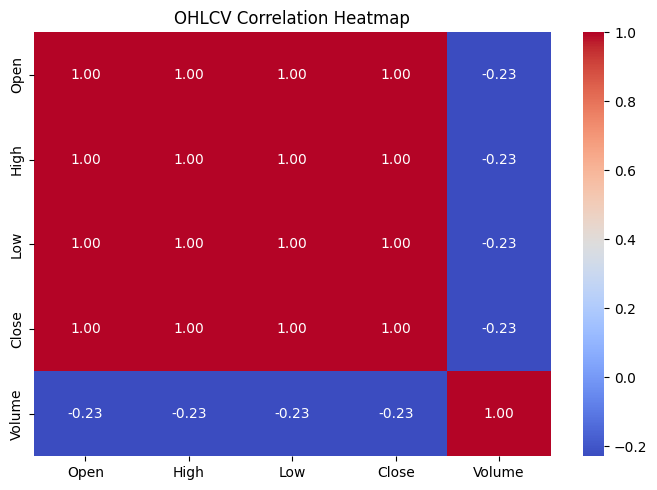

In [15]:
# Graph 5: OHLCV Correlation Heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(df[['Open','High','Low','Close','Volume']].corr(),
            annot=True, fmt='.2f', cmap='coolwarm')
plt.title('OHLCV Correlation Heatmap')
plt.tight_layout()
plt.show()

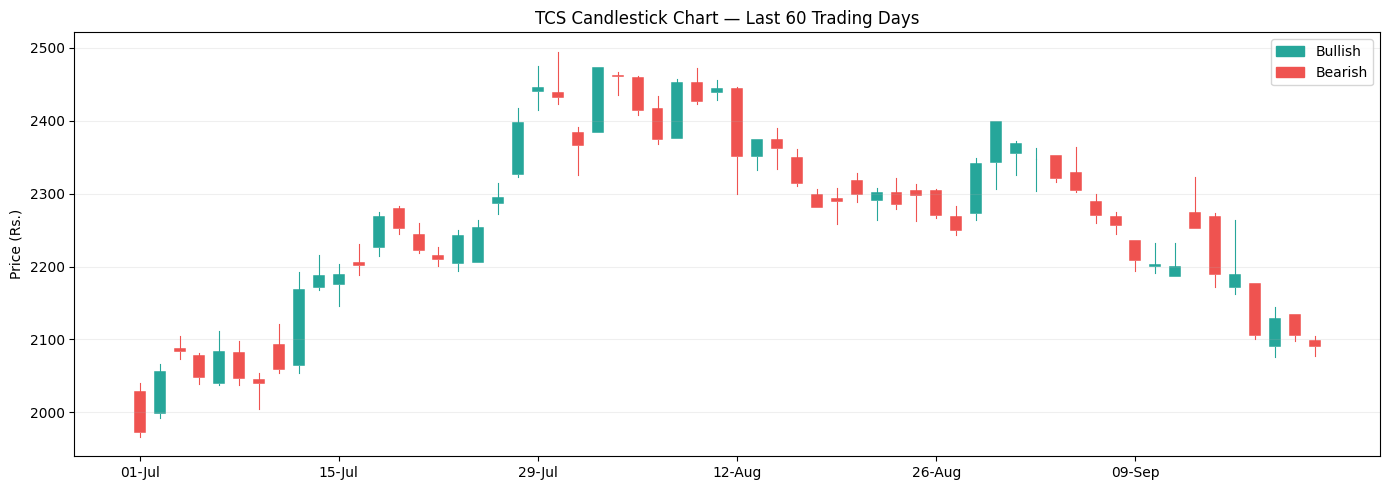

In [16]:
# Graph 6: Candlestick — Last 60 Days
import matplotlib.patches as mpatches
last60 = df.tail(60).copy()
fig, ax = plt.subplots(figsize=(14, 5))
for i, (date, row) in enumerate(last60.iterrows()):
    c = '#26A69A' if row['Close'] >= row['Open'] else '#EF5350'
    ax.bar(i, abs(row['Close']-row['Open']), bottom=min(row['Open'],row['Close']),
           color=c, width=0.6, edgecolor='white', linewidth=0.3)
    ax.plot([i,i],[max(row['Open'],row['Close']), row['High']], color=c, linewidth=0.8)
    ax.plot([i,i],[min(row['Open'],row['Close']), row['Low']],  color=c, linewidth=0.8)
ticks = range(0, 60, 10)
ax.set_xticks(ticks)
ax.set_xticklabels([last60.index[i].strftime('%d-%b') for i in ticks])
ax.set_title('TCS Candlestick Chart — Last 60 Trading Days')
ax.set_ylabel('Price (Rs.)')
ax.legend(handles=[mpatches.Patch(color='#26A69A', label='Bullish'),
                   mpatches.Patch(color='#EF5350', label='Bearish')])
ax.grid(True, alpha=0.2, axis='y')
plt.tight_layout()
plt.show()

---
## Step 5: Create Target Variable
`Next_Day_Close = Close.shift(-1)` — each row now stores tomorrow's closing price.
Last row gets NaN (no tomorrow) — drop it.

In [17]:
df['Next_Day_Close'] = df['Close'].shift(-1)
df.dropna(subset=['Next_Day_Close'], inplace=True)
print(f"Target created. Total rows: {len(df)}")
df[['Close', 'Next_Day_Close']].head(5)

Target created. Total rows: 5362


,Close,Next_Day_Close
Date,,
2005-01-03,108.272697,107.312576
2005-01-04,107.312576,106.011681
2005-01-05,106.011681,105.648384
2005-01-06,105.648384,107.208611
2005-01-07,107.208611,106.208519


### Feature Engineering — Research Paper Basis

The following technical indicators were selected based on their proven effectiveness in stock price prediction literature:

| Indicator | Research Basis | What it captures |
|-----------|---------------|-----------------|
| **MA_7, MA_30** | Brock et al. (1992) | Short/long-term price trends |
| **EMA_12, EMA_26** | Murphy (1999) | Exponentially weighted recent trends |
| **MACD** | Appel (1979) | Price momentum and direction change |
| **RSI_14** | Wilder (1978) | Overbought/oversold market sentiment |
| **Volatility** | Engle (1982) | Risk and price instability measure |
| **Daily_Return** | Fama (1965) | Daily percentage price movement |
| **Lag1_Close** | Box & Jenkins (1970) | Autoregressive: past price predicts future |

> *Key sources:*
> - *Patel et al. (2015). Predicting stock price index movement using ML. Expert Systems with Applications.*
> - *Fischer & Krauss (2018). Deep learning with long short-term memory networks for financial market predictions.*
> - *Brock, Lakonishok & LeBaron (1992). Simple technical trading rules and stochastic properties of stock returns.*

**Why these 9 indicators on top of OHLCV?**
> Raw OHLCV data captures WHAT happened (prices, volume).
> Technical indicators capture WHY it happened (momentum, trend, volatility).
> Combining both gives the model both historical context AND market sentiment.

---
## Step 6: Compute Technical Indicators
All from past/current data — no future leakage.

In [18]:
df2 = df.copy()
df2['MA_7']         = df2['Close'].rolling(7).mean()
df2['MA_30']        = df2['Close'].rolling(30).mean()
df2['EMA_12']       = df2['Close'].ewm(span=12, adjust=False).mean()
df2['EMA_26']       = df2['Close'].ewm(span=26, adjust=False).mean()
df2['MACD']         = df2['EMA_12'] - df2['EMA_26']
delta = df2['Close'].diff()
gain  = delta.clip(lower=0).rolling(14).mean()
loss  = (-delta).clip(lower=0).rolling(14).mean()
df2['RSI_14']       = 100 - (100 / (1 + gain/loss))
df2['Daily_Return'] = df2['Close'].pct_change() * 100
df2['Volatility']   = df2['Daily_Return'].rolling(7).std()
df2['Lag1_Close']   = df2['Close'].shift(1)
df2.dropna(inplace=True)
print(f"Indicators computed. Rows: {len(df2)}")

Indicators computed. Rows: 5333


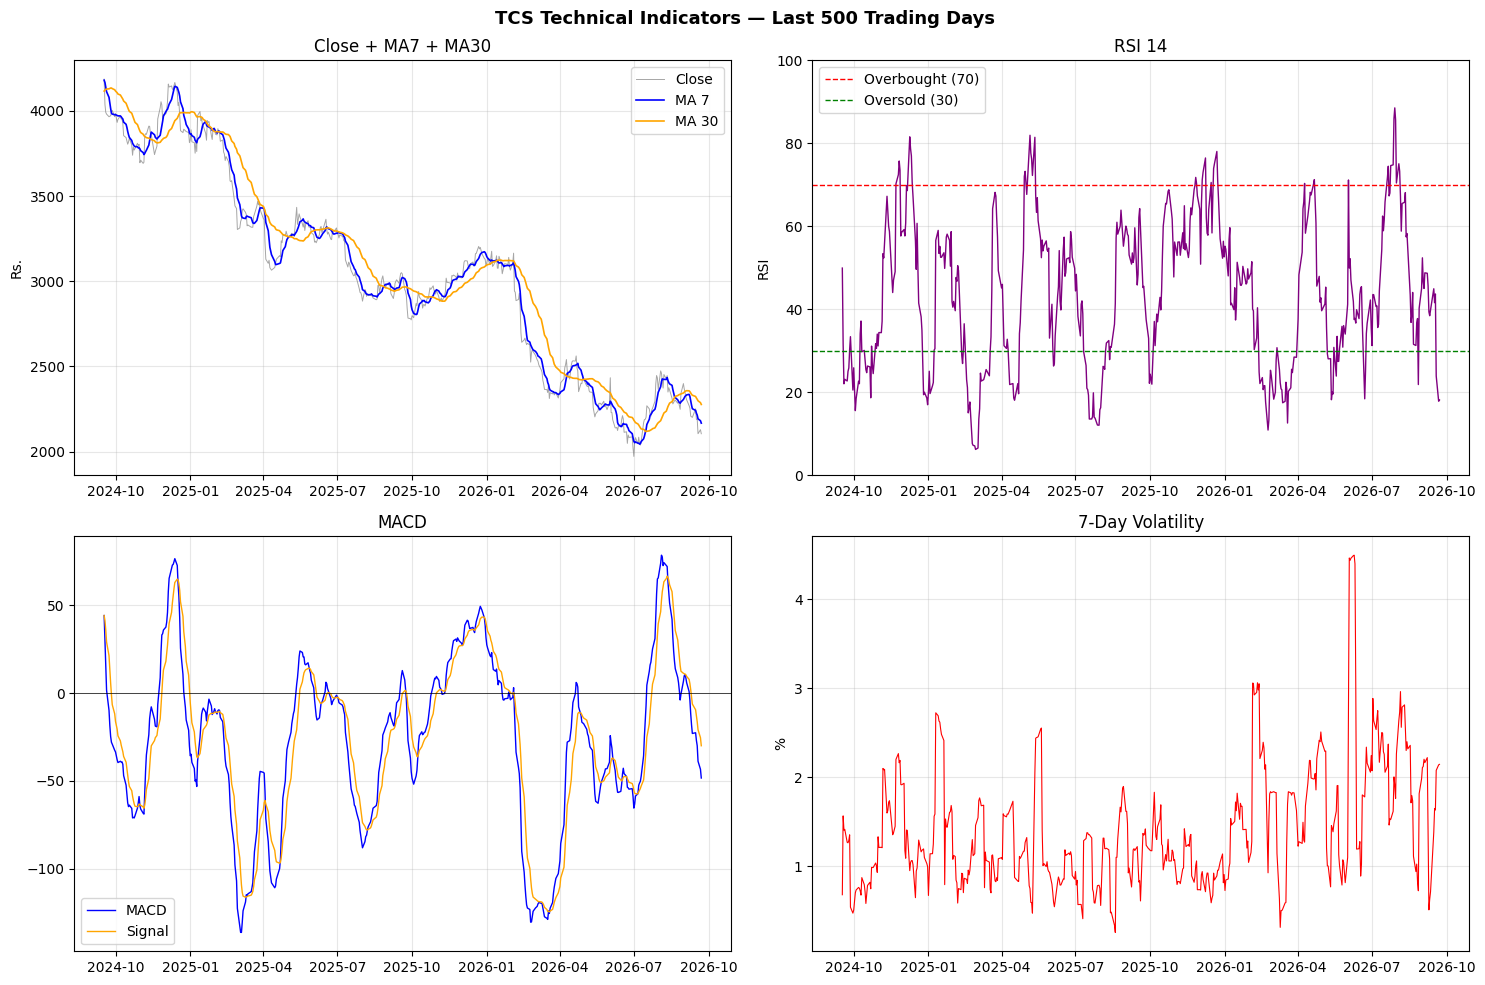

In [19]:
# Indicator Graphs — Last 500 days
plot_df = df2.tail(500).copy()
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('TCS Technical Indicators — Last 500 Trading Days', fontsize=13, fontweight='bold')

# MA7 + MA30
ax = axes[0,0]
ax.plot(plot_df.index, plot_df['Close'], color='gray',   lw=0.7, alpha=0.7, label='Close')
ax.plot(plot_df.index, plot_df['MA_7'],  color='blue',   lw=1.2, label='MA 7')
ax.plot(plot_df.index, plot_df['MA_30'], color='orange', lw=1.2, label='MA 30')
ax.set_title('Close + MA7 + MA30'); ax.set_ylabel('Rs.'); ax.legend(); ax.grid(alpha=0.3)

# RSI
ax = axes[0,1]
ax.plot(plot_df.index, plot_df['RSI_14'], color='purple', lw=1.0)
ax.axhline(70, color='red',   linestyle='--', lw=1.0, label='Overbought (70)')
ax.axhline(30, color='green', linestyle='--', lw=1.0, label='Oversold (30)')
ax.set_title('RSI 14'); ax.set_ylabel('RSI'); ax.set_ylim(0,100); ax.legend(); ax.grid(alpha=0.3)

# MACD
ax = axes[1,0]
signal = plot_df['MACD'].ewm(span=9, adjust=False).mean()
ax.plot(plot_df.index, plot_df['MACD'], color='blue',   lw=1.0, label='MACD')
ax.plot(plot_df.index, signal,           color='orange', lw=1.0, label='Signal')
ax.axhline(0, color='black', lw=0.5)
ax.set_title('MACD'); ax.legend(); ax.grid(alpha=0.3)

# Volatility
ax = axes[1,1]
ax.plot(plot_df.index, plot_df['Volatility'], color='red', lw=0.8)
ax.set_title('7-Day Volatility'); ax.set_ylabel('%'); ax.grid(alpha=0.3)

plt.tight_layout(); plt.show()

---
## Step 7: Define Feature Sets and 80/20 Train/Test Split

In [20]:
SET_A = ['Open','High','Low','Close','Volume']     # 5 features
SET_B = ['Open','High','Low','Close','Volume',
         'MA_7','MA_30','EMA_12','EMA_26',
         'MACD','RSI_14','Volatility','Daily_Return','Lag1_Close']  # 14 features

# Align both to same rows
common_idx = df2.index
X_A = df.loc[common_idx, SET_A]
X_B = df2[SET_B]
y   = df.loc[common_idx, 'Next_Day_Close']

# 80/20 time-based (NO random shuffle)
split = int(len(df2) * 0.80)
X_A_train, X_A_test = X_A.iloc[:split], X_A.iloc[split:]
X_B_train, X_B_test = X_B.iloc[:split], X_B.iloc[split:]
y_train, y_test     = y.iloc[:split],   y.iloc[split:]

print(f"Train rows: {len(y_train)}")
print(f"Test  rows: {len(y_test)}")

Train rows: 4266
Test  rows: 1067


---
## Step 7b: Data Inspection — Feature Distributions & Train/Test Shift
> **Before training any model**, we inspect the feature distributions (Set A vs Set B), 
> compare Train and Test price levels, and flag any data quality issues (zero-volume days).
> This section does **not** change any modelling variable — it is read-only analysis.

In [21]:
# ── EDA 1: describe() for Set A and Set B (same rows used for modelling) ─────
import pandas as pd

print('=' * 60)
print('Set A — OHLCV (5 features), modelling rows only')
print('=' * 60)
display(X_A.describe().round(2))

print()
print('=' * 60)
print('Set B — OHLCV + Indicators (14 features), same rows')
print('=' * 60)
display(X_B.describe().round(2))

print(f'\nBoth sets share {len(X_A)} rows (NaN rows already dropped).')

Set A — OHLCV (5 features), modelling rows only


,Open,High,Low,Close,Volume
count,5333.00,5333.00,5333.00,5333.00,5333.00
mean,1351.04,1364.38,1336.82,1350.27,3326256.81
std,1188.71,1198.84,1178.08,1188.05,2778885.48
min,75.80,78.58,69.43,75.49,0.00
25%,283.45,287.54,281.35,284.65,1848566.00
50%,961.44,969.28,952.30,959.80,2642976.00
75%,2392.58,2426.01,2364.79,2396.59,3968866.00
max,4251.38,4266.48,4191.92,4230.71,88067154.00



Set B — OHLCV + Indicators (14 features), same rows


,Open,High,Low,Close,Volume,MA_7,MA_30,EMA_12,EMA_26,MACD,RSI_14,Volatility,Daily_Return,Lag1_Close
count,5333.00,5333.00,5333.00,5333.00,5333.00,5333.00,5333.00,5333.00,5333.00,5333.00,5333.00,5333.00,5333.00,5333.00
mean,1351.04,1364.38,1336.82,1350.27,3326256.81,1349.13,1344.47,1348.12,1345.26,2.85,52.61,1.67,0.08,1349.89
std,1188.71,1198.84,1178.08,1188.05,2778885.48,1187.95,1187.57,1187.61,1187.08,27.90,16.44,1.82,2.40,1188.13
min,75.80,78.58,69.43,75.49,0.00,78.60,82.77,79.96,81.55,-136.34,6.23,0.25,-50.61,75.49
25%,283.45,287.54,281.35,284.65,1848566.00,280.72,275.54,277.92,274.17,-4.17,40.56,1.01,-0.85,284.05
50%,961.44,969.28,952.30,959.80,2642976.00,961.98,964.55,960.60,963.59,2.02,52.97,1.39,0.03,959.73
75%,2392.58,2426.01,2364.79,2396.59,3968866.00,2393.19,2384.21,2381.74,2371.46,11.31,64.60,1.94,0.96,2396.59
max,4251.38,4266.48,4191.92,4230.71,88067154.00,4194.66,4134.20,4176.54,4132.32,120.28,97.54,45.18,100.00,4230.71



Both sets share 5333 rows (NaN rows already dropped).


In [22]:
# ── EDA 2: Train vs Test Close stats + Volume==0 ────────────────────────────

# --- Train / Test describe for Close ---
close_train = X_A_train['Close']
close_test  = X_A_test['Close']

print('Close Price — TRAIN set')
display(close_train.describe().to_frame().T.round(2))

print('Close Price — TEST set')
display(close_test.describe().to_frame().T.round(2))

# --- Small comparison table ---
comp = pd.DataFrame({
    'Split' : ['Train', 'Test'],
    'Min (Rs)' : [round(close_train.min(), 2), round(close_test.min(), 2)],
    'Mean (Rs)': [round(close_train.mean(), 2), round(close_test.mean(), 2)],
    'Max (Rs)' : [round(close_train.max(), 2), round(close_test.max(), 2)],
})
pct_above = (close_test > close_train.max()).mean() * 100
print('\nTrain vs Test Close Summary')
display(comp)
print(f'% of Test rows where Close > Training Maximum ({round(close_train.max(),2)}): '
      f'{pct_above:.2f}%')

# --- Volume == 0 ---
vol_zero_full = (X_A['Volume'] == 0).sum()
vol_zero_train = (X_A_train['Volume'] == 0).sum()
vol_zero_test  = (X_A_test['Volume'] == 0).sum()
print(f'\nRows with Volume == 0: {vol_zero_full} total '
      f'({vol_zero_train} train, {vol_zero_test} test)')

Close Price — TRAIN set


,count,mean,std,min,25%,50%,75%,max
Close,4266.0,903.02,837.82,75.49,201.22,735.02,1155.77,3498.13


Close Price — TEST set


,count,mean,std,min,25%,50%,75%,max
Close,1067.0,3138.44,500.55,1971.79,2874.07,3079.28,3516.16,4230.71



Train vs Test Close Summary


,Split,Min (Rs),Mean (Rs),Max (Rs)
0,Train,75.49,903.02,3498.13
1,Test,1971.79,3138.44,4230.71


% of Test rows where Close > Training Maximum (3498.13): 25.40%

Rows with Volume == 0: 9 total (7 train, 2 test)


---
### Note: Feature Scales and Test-Period Price Regime

**Feature scale mismatch:**
The features used in Set B operate on very different numerical scales:

| Feature | Typical Range | Unit |
|:--------|:-------------|:----|
| RSI_14 | 0 – 100 | dimensionless |
| Daily_Return | ≈ −5 to +5 | % per day |
| Volume | 100,000 – 50,000,000 | shares/day |
| Close / Open / High / Low | 100 – 4,500 | INR |
| MACD | −20 to +20 | INR |

Because of this scale mismatch, **StandardScaler is applied for Ridge, Lasso, Elastic Net, SVR and KNN** 
(distance- or regularisation-based models are sensitive to feature magnitudes). 
Simple Linear Regression, Decision Tree, Random Forest, Gradient Boosting and XGBoost 
are scale-invariant and do not need scaling.

**Train → Test regime shift:**  
As seen in the table above, the **test period has a substantially higher price level** than 
the training period. Tree-based models cannot extrapolate beyond the training price range, 
which explains their high error on the test set when predicting price directly.  
This is why a *next-day return* formulation (predicting % change, then converting back to price) 
is explored later in the notebook.

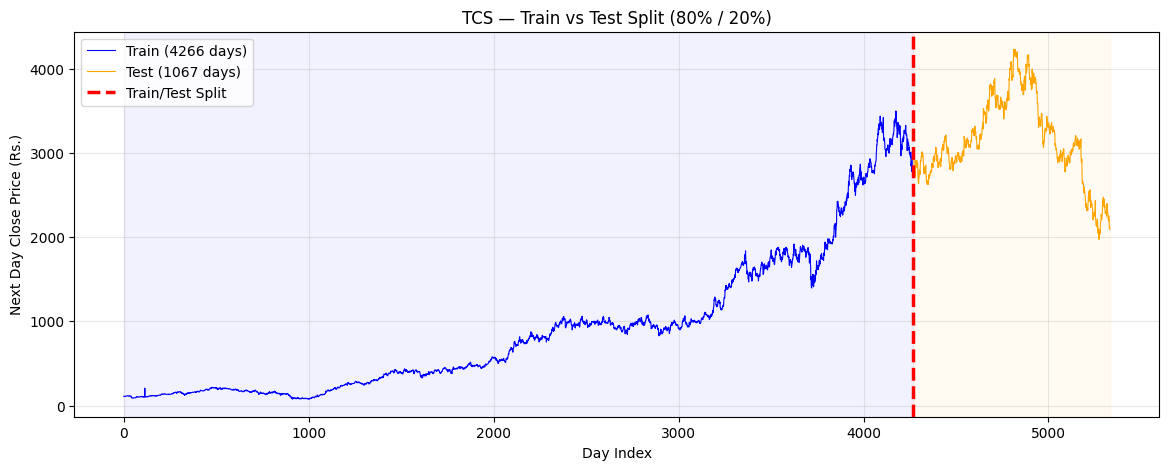

Train: 2005-02-15 to 2022-05-30
Test : 2022-05-31 to 2026-09-22


In [23]:
# Train vs Test Split Visualization
n_tr = len(y_train); n_te = len(y_test)

plt.figure(figsize=(14, 5))
plt.plot(range(n_tr), y_train.values, color='blue', lw=0.8, label=f'Train ({n_tr} days)')
plt.plot(range(n_tr, n_tr+n_te), y_test.values, color='orange', lw=0.8, label=f'Test ({n_te} days)')
plt.axvline(n_tr, color='red', lw=2.5, linestyle='--', label='Train/Test Split')
plt.axvspan(0, n_tr,       alpha=0.05, color='blue')
plt.axvspan(n_tr, n_tr+n_te, alpha=0.05, color='orange')
plt.title('TCS — Train vs Test Split (80% / 20%)')
plt.xlabel('Day Index'); plt.ylabel('Next Day Close Price (Rs.)')
plt.legend(); plt.grid(True, alpha=0.3)
plt.show()
print(f"Train: {y_train.index[0].date()} to {y_train.index[-1].date()}")
print(f"Test : {y_test.index[0].date()} to {y_test.index[-1].date()}")

---
## Step 8: Helper Functions

In [24]:
def get_metrics(y_true, y_pred):
    y_true = np.array(y_true); y_pred = np.array(y_pred)
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    da   = np.mean(np.sign(np.diff(y_true)) == np.sign(np.diff(y_pred))) * 100
    return {'MAE': mae, 'RMSE': rmse, 'R2': r2, 'MAPE': mape, 'Dir_Acc': da}

def print_metrics(m, name):
    print(f"{'='*45}\n  {name}\n{'='*45}")
    print(f"  MAE          : Rs {m['MAE']:.2f}")
    print(f"  RMSE         : Rs {m['RMSE']:.2f}")
    print(f"  R2 Score     : {m['R2']:.6f}")
    print(f"  MAPE         : {m['MAPE']:.4f}%")
    print(f"  Dir. Accuracy: {m['Dir_Acc']:.2f}%")

print("Helper functions ready!")

Helper functions ready!


---
---
# Part A: Linear Regression — OHLCV Only (5 Features)
**Features:** Open, High, Low, Close, Volume

In [25]:
# Features: OHLCV (5 columns)
X_train_A = X_A_train
X_test_A  = X_A_test
print(f"Features: {list(X_train_A.columns)}")
print(f"Train shape: {X_train_A.shape}")

Features: ['Open', 'High', 'Low', 'Close', 'Volume']
Train shape: (4266, 5)


In [26]:
# Train the model
lr_A = LinearRegression()
lr_A.fit(X_train_A, y_train)
print("Model trained successfully!")

Model trained successfully!


In [27]:
# Predict on test set
y_pred_A = lr_A.predict(X_test_A)
print("First 10 Predictions:")
print(y_pred_A[:10])

First 10 Predictions:
[2953.60531279 2945.77178009 3005.0687989  3021.86438933 3011.45807027
 2954.40741716 2987.36735002 3007.4465598  2951.00057852 2826.95663311]


In [28]:
# Model coefficients
coeff = pd.DataFrame({'Feature': X_train_A.columns, 'Coefficient': lr_A.coef_})
print(f"Intercept: {lr_A.intercept_:.4f}")
print("Coefficients:")
print(coeff.to_string(index=False))

Intercept: 0.2933
Coefficients:
Feature   Coefficient
   Open -6.382307e-02
   High  8.744035e-02
    Low  7.525973e-02
  Close  9.013584e-01
 Volume  1.336930e-08


In [29]:
# Comparison Table: Date, Actual, Predicted, Difference
comparison_A = pd.DataFrame({
    'Date'                    : y_test.index,
    'Actual Next Day Close'   : y_test.values,
    'Predicted Next Day Close': y_pred_A,
})
comparison_A['Difference'] = (comparison_A['Actual Next Day Close']
                              - comparison_A['Predicted Next Day Close'])
print("First 10 rows:")
print(comparison_A.head(10).to_string(index=False))

First 10 rows:
      Date  Actual Next Day Close  Predicted Next Day Close  Difference
2022-05-31            2945.086182               2953.605313   -8.519131
2022-06-01            3004.599365               2945.771780   58.827585
2022-06-02            3019.653076               3005.068799   14.584277
2022-06-03            3011.577637               3021.864389  -10.286753
2022-06-06            2951.669922               3011.458070  -59.788148
2022-06-07            2988.053223               2954.407417   33.645805
2022-06-08            3008.198242               2987.367350   20.830892
2022-06-09            2949.212158               3007.446560  -58.234402
2022-06-10            2826.061523               2951.000579 -124.939055
2022-06-13            2818.117676               2826.956633   -8.838957


In [30]:
# Compute Metrics
metrics_A = get_metrics(y_test, y_pred_A)
print_metrics(metrics_A, "Linear Regression — OHLCV Only")

  Linear Regression — OHLCV Only
  MAE          : Rs 31.17
  RMSE         : Rs 43.43
  R2 Score     : 0.992495
  MAPE         : 1.0144%
  Dir. Accuracy: 50.19%


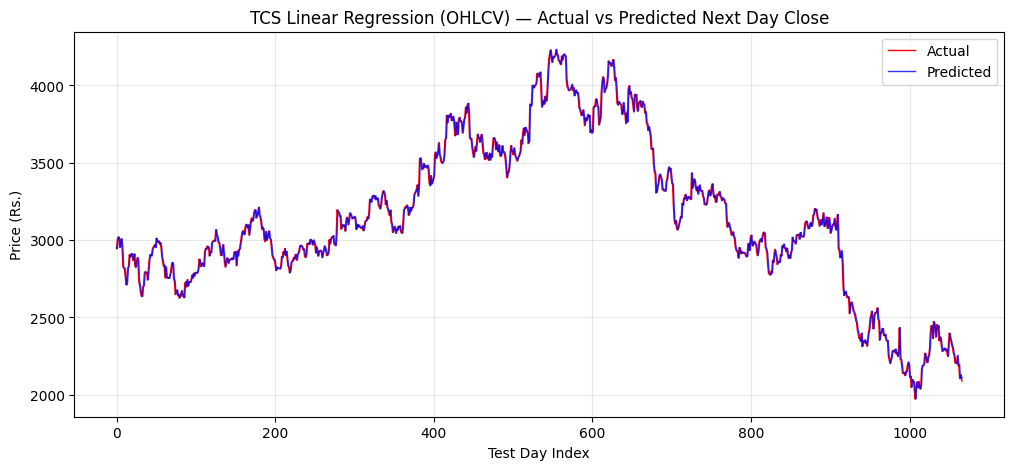

In [31]:
# Graph 1: Actual vs Predicted (line)
plt.figure(figsize=(12, 5))
plt.plot(y_test.values, color='red',  linewidth=1.0, label='Actual')
plt.plot(y_pred_A,       color='blue', linewidth=1.0, label='Predicted', alpha=0.8)
plt.xlabel('Test Day Index')
plt.ylabel('Price (Rs.)')
plt.title('TCS Linear Regression (OHLCV) — Actual vs Predicted Next Day Close')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Why Scatter Plot? (Research Justification)

**Actual vs Predicted Scatter Plot:**
> A scatter plot of actual values (x-axis) vs predicted values (y-axis) is a standard diagnostic tool
> in regression model evaluation (James et al., 2013 — Introduction to Statistical Learning).
>
> **Perfect model:** All points lie exactly on the diagonal line (y = x).
> **What to look for:**
> - Points clustered tightly around y = x → model is accurate
> - Systematic curve above/below diagonal → model has bias
> - Fan shape (spread increases) → heteroscedasticity / variance changes with price level
>
> *Source: James, G., Witten, D., Hastie, T., Tibshirani, R. (2013). An Introduction to Statistical Learning.*

This graph complements the residual plot — together they give a complete picture of model error patterns.

### Why RSI and MACD? (Literature Basis — Tested Here)

**Indicators chosen based on published research:**

| Indicator | Source |
|-----------|--------|
| **RSI (Relative Strength Index)** | Wilder, J.W. (1978). *New Concepts in Technical Trading Systems.* |
| **MACD** | Appel, G. (1979). *The MACD Trading Method.* |
| **RSI + MACD in ML** | Mehtab, S., Sen, J., & Dutta, A. (2021). *Stock Price Prediction Using Machine Learning and LSTM-Based Deep Learning Models.* Springer. |

> **What Mehtab, Sen & Dutta (2021) found:**
> RSI and MACD, alongside Moving Averages, are among the most commonly used
> technical indicators as input features in ML-based stock price prediction models.

**What we found on TCS data:**
> In this dataset, adding RSI and MACD (along with 7 other indicators) gave
> **no meaningful improvement** over raw OHLCV features.
> The MAPE slightly worsened or stayed the same for Linear Regression.
> This is consistent with stock prediction literature — for near-linear assets
> like large-cap IT stocks, raw price features already carry most of the signal.

> **Note:** Indicators are still worth testing — on volatile stocks or short timeframes
> they may add value. Their inclusion here follows standard ML practice for financial data.

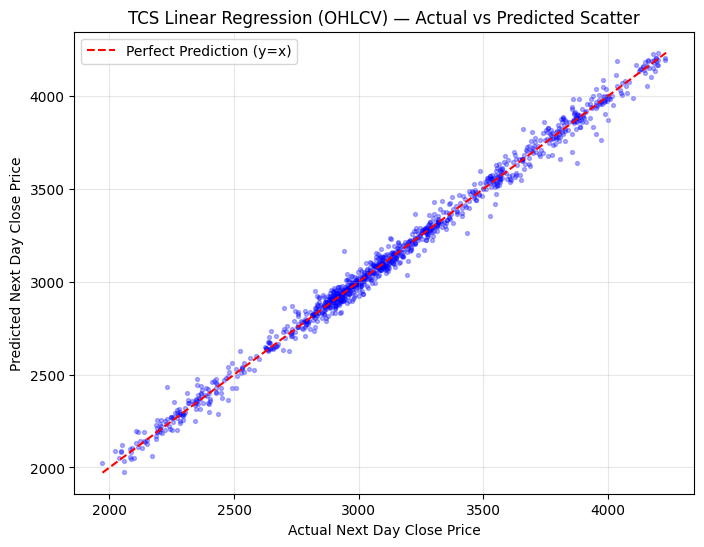

In [32]:
# Graph 2: Scatter with y=x line
plt.figure(figsize=(8, 6))
plt.scatter(y_test.values, y_pred_A, alpha=0.3, s=8, color='blue')
mn = min(y_test.min(), y_pred_A.min())
mx = max(y_test.max(), y_pred_A.max())
plt.plot([mn, mx], [mn, mx], 'r--', linewidth=1.5, label='Perfect Prediction (y=x)')
plt.xlabel('Actual Next Day Close Price')
plt.ylabel('Predicted Next Day Close Price')
plt.title('TCS Linear Regression (OHLCV) — Actual vs Predicted Scatter')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

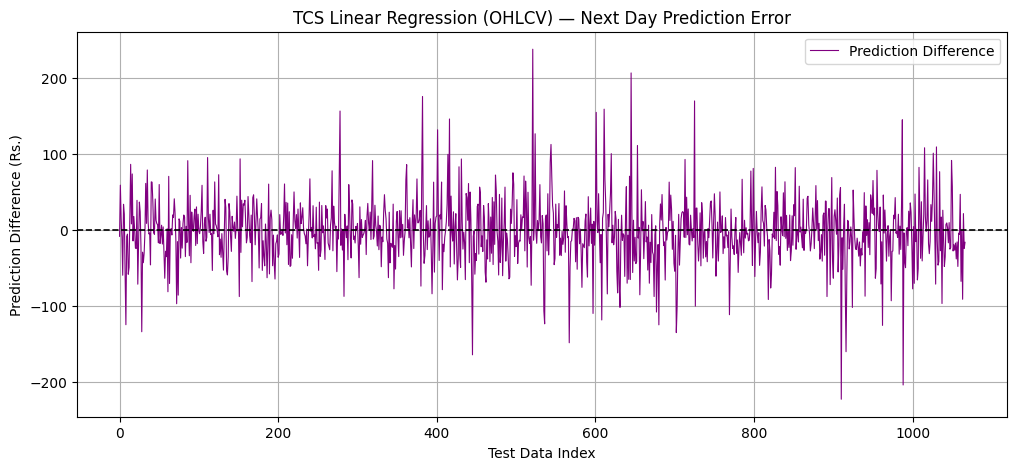

In [33]:
# Graph 3: Residuals (Prediction Error)
residuals_A = y_test.values - y_pred_A

plt.figure(figsize=(12, 5))
plt.plot(residuals_A, color='purple', linewidth=0.8, label='Prediction Difference')
plt.axhline(0, color='black', linestyle='--', linewidth=1.2)
plt.xlabel('Test Data Index')
plt.ylabel('Prediction Difference (Rs.)')
plt.title('TCS Linear Regression (OHLCV) — Next Day Prediction Error')
plt.legend()
plt.grid(True)
plt.show()

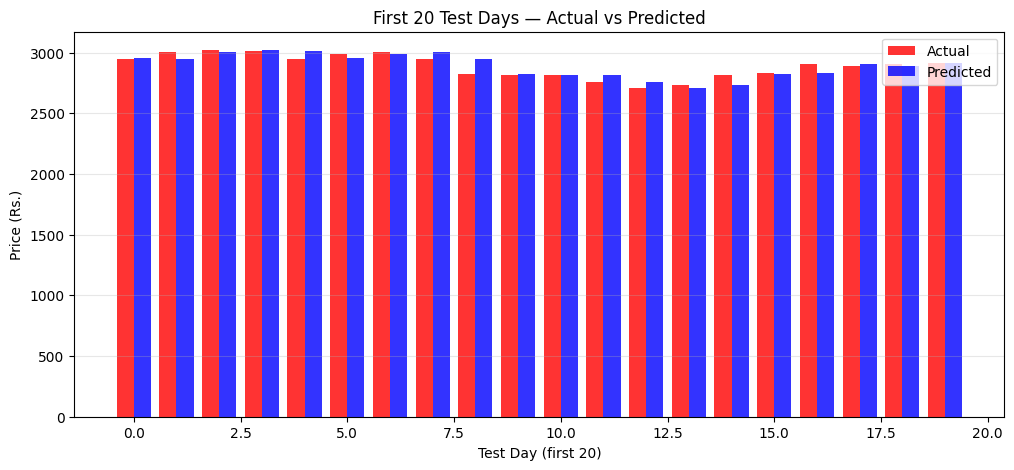

In [34]:
# Graph 4: Bar chart — First 20 test days
x_pos = np.arange(20)
plt.figure(figsize=(12, 5))
plt.bar(x_pos - 0.2, y_test.values[:20], 0.4, label='Actual',    color='red',   alpha=0.8)
plt.bar(x_pos + 0.2, y_pred_A[:20],      0.4, label='Predicted', color='blue',  alpha=0.8)
plt.xlabel('Test Day (first 20)')
plt.ylabel('Price (Rs.)')
plt.title('First 20 Test Days — Actual vs Predicted')
plt.legend()
plt.grid(True, alpha=0.3, axis='y')
plt.show()

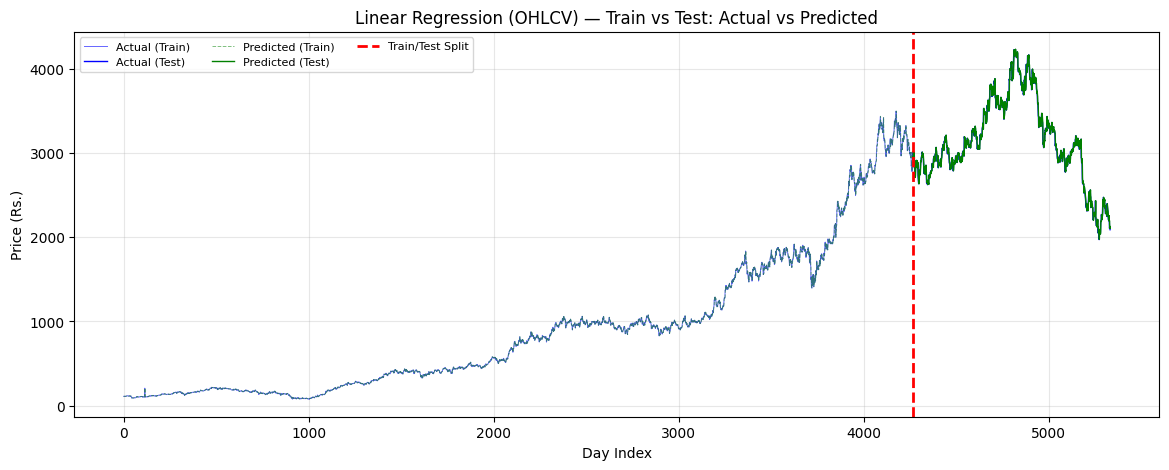

In [35]:
# Train predictions for comparison
y_train_pred_A = lr_A.predict(X_train_A)

# Graph 5: Train vs Test with split line
plt.figure(figsize=(14, 5))
plt.plot(range(n_tr), y_train.values,        color='blue', lw=0.7, alpha=0.6, label='Actual (Train)')
plt.plot(range(n_tr, n_tr+n_te), y_test.values, color='blue', lw=1.0, label='Actual (Test)')
plt.plot(range(n_tr), y_train_pred_A,          color='green', lw=0.7, alpha=0.5, linestyle='--', label='Predicted (Train)')
plt.plot(range(n_tr, n_tr+n_te), y_pred_A,     color='green', lw=1.0, label='Predicted (Test)')
plt.axvline(n_tr, color='red', lw=2, linestyle='--', label='Train/Test Split')
plt.title('Linear Regression (OHLCV) — Train vs Test: Actual vs Predicted')
plt.xlabel('Day Index'); plt.ylabel('Price (Rs.)')
plt.legend(fontsize=8, ncol=3); plt.grid(True, alpha=0.3)
plt.show()

### Overfitting / Underfitting Check — OHLCV Model

> **Overfitting Check Rule:**
> - **OVERFIT:** Test MAPE > 1.5 × Train MAPE  OR  (Train R2 − Test R2) > 0.05
> - **UNDERFIT:** Train R2 < 0.80 (model is poor even on its own training data)
> - **GOOD FIT:** Both errors are low and close to each other
>
> A small positive gap (test MAPE > train MAPE) is **normal and expected** in time-series:
> the test period (2021–2026) contains market events (COVID recovery, rate hikes) not seen in training.

In [36]:
tr_m_A = get_metrics(y_train, y_train_pred_A)

print("="*50)
print("  Overfit Check: LR — OHLCV Only")
print("="*50)
print(f"  Train MAPE : {tr_m_A['MAPE']:.4f}%")
print(f"  Test  MAPE : {metrics_A['MAPE']:.4f}%")
gap_A = metrics_A['MAPE'] - tr_m_A['MAPE']
r2_gap_A = tr_m_A['R2'] - metrics_A['R2']
print(f"  MAPE Gap   : {gap_A:+.4f}%  {'(negative = price-level effect, not overfitting)' if gap_A < 0 else ''}")
print(f"  Train R2   : {tr_m_A['R2']:.6f}")
print(f"  Test  R2   : {metrics_A['R2']:.6f}")
print(f"  R2 Gap     : {r2_gap_A:.6f}  (Train R2 - Test R2)")

# Verdict: OVERFIT if MAPE ratio > 1.5 OR R2 gap > 0.05
if (metrics_A['MAPE'] > 1.5 * tr_m_A['MAPE']) or (r2_gap_A > 0.05):
    verdict = 'OVERFITTING'
elif tr_m_A['R2'] < 0.80:
    verdict = 'UNDERFITTING'
else:
    verdict = 'GOOD FIT'

print(f"  Verdict    : {verdict}")
print()
print("  Rule: OVERFIT if Test MAPE > 1.5x Train MAPE  OR  (Train R2 - Test R2) > 0.05")
print("        UNDERFIT if Train R2 < 0.80")
print("        else GOOD FIT")

  Overfit Check: LR — OHLCV Only
  Train MAPE : 1.3944%
  Test  MAPE : 1.0144%
  MAPE Gap   : -0.3800%  (negative = price-level effect, not overfitting)
  Train R2   : 0.999480
  Test  R2   : 0.992495
  R2 Gap     : 0.006984  (Train R2 - Test R2)
  Verdict    : GOOD FIT

  Rule: OVERFIT if Test MAPE > 1.5x Train MAPE  OR  (Train R2 - Test R2) > 0.05
        UNDERFIT if Train R2 < 0.80
        else GOOD FIT


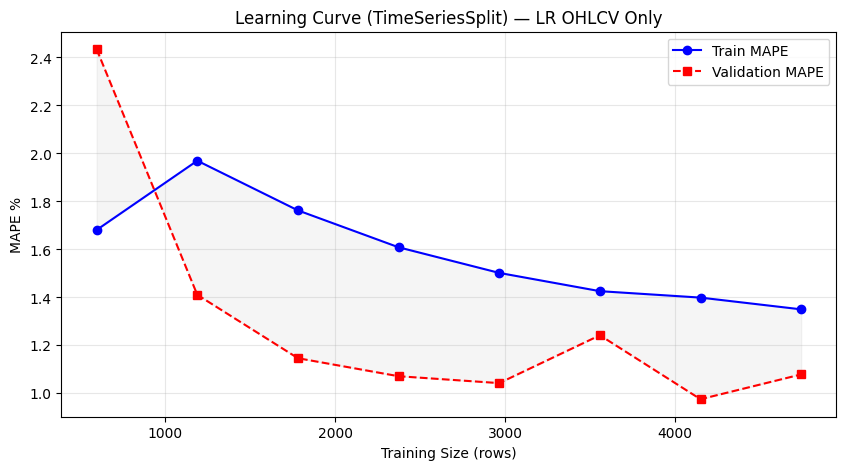

In [37]:
# Learning Curve (TimeSeriesSplit) — OHLCV
tscv = TimeSeriesSplit(n_splits=8)
tr_mapes, val_mapes, sizes = [], [], []

for tr_idx, val_idx in tscv.split(X_A):
    m = LinearRegression()
    m.fit(X_A.iloc[tr_idx], y.iloc[tr_idx])
    tr_mapes.append(get_metrics(y.iloc[tr_idx], m.predict(X_A.iloc[tr_idx]))['MAPE'])
    val_mapes.append(get_metrics(y.iloc[val_idx], m.predict(X_A.iloc[val_idx]))['MAPE'])
    sizes.append(len(tr_idx))

plt.figure(figsize=(10, 5))
plt.plot(sizes, tr_mapes,  'o-', color='blue',  lw=1.5, label='Train MAPE')
plt.plot(sizes, val_mapes, 's--', color='red',   lw=1.5, label='Validation MAPE')
plt.fill_between(sizes, tr_mapes, val_mapes, alpha=0.08, color='gray')
plt.xlabel('Training Size (rows)')
plt.ylabel('MAPE %')
plt.title('Learning Curve (TimeSeriesSplit) — LR OHLCV Only')
plt.legend(); plt.grid(True, alpha=0.3)
plt.show()